# Ejercicio 6: Búsqueda del Mínimo Global con Descenso de Gradiente
**Matemáticas para Inteligencia Artificial**

Función objetivo:
$$f(x_1, x_2) = x_1^4 - 8x_1^2 + 2x_1 + (x_2 - x_1)^2$$

Derivadas parciales (gradiente $\nabla f(x)$):
* $\frac{\partial f}{\partial x_1} = 4x_1^3 - 16x_1 + 2 - 2(x_2 - x_1)$
* $\frac{\partial f}{\partial x_2} = 2(x_2 - x_1)$

En este notebook realizaremos:
1. Implementación de $f(x)$, su gradiente $\nabla f(x)$ y el algoritmo de descenso de gradiente.
2. Selección heurística de $\gamma$ y $x_0$, probando varios valores para observar divergencia, oscilación y convergencia lenta.
3. Ejecución final hasta que $\|\nabla f(x_i)\| < 10^{-6}$ reportando $x^*$, $f(x^*)$, el gradiente final y el número de iteraciones.
4. Gráfica de $f(x_i)$ contra $i$.
5. Exploración con múltiples puntos iniciales para reportar todos los mínimos encontrados, identificar el **mínimo global** y justificar cómo sabemos que es el global.


## 1. Importación de librerías, función objetivo, gradiente y algoritmo


In [1]:
import numpy as np              # Para operaciones con vectores, normas y raíces
import pandas as pd             # Para resumir pruebas y resultados en tablas
import matplotlib.pyplot as plt # Para graficar convergencia y curvas de nivel

# Inciso 1: Función objetivo f(x1, x2) = x1^4 - 8*x1^2 + 2*x1 + (x2 - x1)^2
def f(x):
    x1, x2 = x[0], x[1]
    return (x1**4) - 8.0*(x1**2) + 2.0*x1 + (x2 - x1)**2

# Gradiente analítico de f(x1, x2)
def gradiente(x):
    x1, x2 = x[0], x[1]
    df_dx1 = 4.0*(x1**3) - 16.0*x1 + 2.0 - 2.0*(x2 - x1)
    df_dx2 = 2.0*(x2 - x1)
    return np.array([df_dx1, df_dx2], dtype=float)

# Función reutilizable de Descenso de Gradiente
def descenso_gradiente(x0, gamma, tolerancia=1e-6, max_iter=5000):
    x = np.array(x0, dtype=float)
    historial = []
    estado = "No convergió (límite de iteraciones)"

    for i in range(max_iter):
        grad = gradiente(x)
        norma_grad = np.linalg.norm(grad)
        valor_f = f(x)

        # Detección de divergencia (valores infinitos, NaN o muy grandes)
        if np.isnan(norma_grad) or np.isinf(norma_grad) or norma_grad > 1e12:
            estado = "Diverge"
            break

        historial.append({
            "i": i,
            "x1": x[0],
            "x2": x[1],
            "grad_x1": grad[0],
            "grad_x2": grad[1],
            "||grad||": norma_grad,
            "f(x_i)": valor_f
        })

        # Criterio de paro: ||gradiente|| < tolerancia
        if norma_grad < tolerancia:
            estado = "Converge"
            break

        # Regla de actualización: x_{i+1} = x_i - gamma * gradiente
        x = x - gamma * grad

    return pd.DataFrame(historial), estado

## 2. Selección heurística de $\gamma$ y $x_0$


In [2]:
# Inciso 2a: Probamos distintas tasas de aprendizaje gamma partiendo desde x0 = [0.0, 0.0]
x0_base = [0.0, 0.0]
gammas_prueba = [0.2, 0.1, 0.06, 0.05, 0.04, 0.03, 0.01, 0.002]

resultados_gamma = []
for g in gammas_prueba:
    df_p, estado = descenso_gradiente(x0_base, gamma=g, tolerancia=1e-6, max_iter=5000)
    ultima = df_p.iloc[-1]
    
    if estado == "No convergió (límite de iteraciones)":
        estado = "Oscila (no converge)"
        
    resultados_gamma.append({
        "gamma": g,
        "Estado": estado,
        "Iteraciones": int(ultima["i"]),
        "x* final": f"[{ultima['x1']:.4f}, {ultima['x2']:.4f}]",
        "f(x) final": round(ultima["f(x_i)"], 6),
        "||grad|| final": f"{ultima['||grad||']:.2e}"
    })

print("Pruebas variando gamma (con x0 = [0.0, 0.0]):")
tabla_gammas = pd.DataFrame(resultados_gamma)
tabla_gammas

Pruebas variando gamma (con x0 = [0.0, 0.0]):


,gamma,Estado,Iteraciones,x* final,f(x) final,||grad|| final
0,0.200,Diverge,8,"[29.8784, -0.8579]",790814.519368,1.06e+05
1,0.100,Oscila (no converge),4999,"[0.5769, 1.5760]",-0.399807,8.69e+00
2,0.060,Oscila (no converge),4999,"[-2.3195, -1.9512]",-18.599094,1.16e+01
3,0.050,Converge,158,"[-2.0598, -2.0598]",-20.060660,9.53e-07
4,0.040,Converge,199,"[-2.0598, -2.0598]",-20.060660,9.66e-07
5,0.030,Converge,267,"[-2.0598, -2.0598]",-20.060660,9.97e-07
6,0.010,Converge,814,"[-2.0598, -2.0598]",-20.060660,9.99e-07
7,0.002,Converge,4096,"[-2.0598, -2.0598]",-20.060660,9.99e-07


### Conclusión de la selección heurística de $\gamma$ y $x_0$
* **Elección de $\gamma = 0.04$:**
  * Con $\gamma = 0.2$ el algoritmo **diverge** en pocas iteraciones por el término $4x_1^3$ del gradiente.
  * Con $\gamma = 0.1$ y $\gamma = 0.06$ el método **oscila** sin lograr estabilizarse (la norma del gradiente se queda alrededor de $10$).
  * Con $\gamma = 0.002$ converge, pero **muy lento** (4,096 iteraciones).
  * Aunque $\gamma = 0.05$ converge en 158 iteraciones, está muy cerca del límite de oscilación ($0.06$). Elegimos **$\gamma = 0.04$** porque converge rápido (**199 iteraciones**) y mantiene un margen seguro de estabilidad incluso al probar puntos iniciales más alejados (como $[-3, -3]$ o $[3, 3]$).
* **Elección de $x_0 = [0.0, 0.0]$ para el reporte principal:**
  * Como se comprobará en la Sección 5 al explorar varios puntos iniciales, la función tiene dos mínimos y $x_0 = [0.0, 0.0]$ cae en la cuenca de atracción del **mínimo global** ($x^* \approx [-2.0598, -2.0598]$).
* **Límite de iteraciones:** Se eligió `max_iter = 5000` para dar margen holgado incluso a tasas pequeñas (como $\gamma = 0.002$) y distinguir claramente convergencia lenta de oscilación.


## 3. Ejecución final y reporte del mínimo global encontrado


In [3]:
# Inciso 3: Ejecutamos el método con los parámetros elegidos heurísticamente
x0_elegido = [0.0, 0.0]
gamma_elegido = 0.04
tolerancia = 1e-6

tabla, estado = descenso_gradiente(x0_elegido, gamma=gamma_elegido, tolerancia=tolerancia, max_iter=5000)
final = tabla.iloc[-1]

print("=== RESULTADO FINAL (EJERCICIO 6) ===")
print(f"Estado:               {estado}")
print(f"Parámetros elegidos:  gamma = {gamma_elegido}, x0 = {x0_elegido}")
print(f"Iteraciones totales:  {int(final['i'])}")
print(f"Mínimo encontrado x*: [{final['x1']:.6f}, {final['x2']:.6f}]")
print(f"Valor mínimo f(x*):   {final['f(x_i)']:.6f}")
print(f"Gradiente final:      [{final['grad_x1']:.2e}, {final['grad_x2']:.2e}]")
print(f"Norma del gradiente:  {final['||grad||']:.2e}")

=== RESULTADO FINAL (EJERCICIO 6) ===
Estado:               Converge
Parámetros elegidos:  gamma = 0.04, x0 = [0.0, 0.0]
Iteraciones totales:  199
Mínimo encontrado x*: [-2.059792, -2.059791]
Valor mínimo f(x*):   -20.060660
Gradiente final:      [5.51e-08, 9.64e-07]
Norma del gradiente:  9.66e-07


## 4. Gráfica de $f(x_i)$ contra $i$


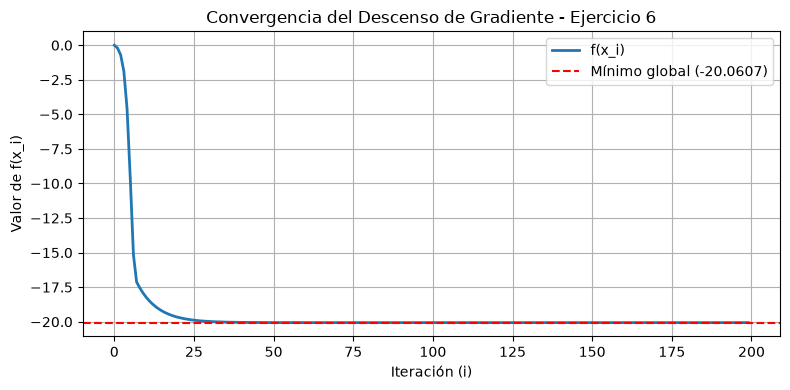

In [4]:
# Inciso 4: Graficamos el descenso de f(x_i) a lo largo de las iteraciones
plt.figure(figsize=(8, 4))
plt.plot(tabla["i"], tabla["f(x_i)"], linewidth=2, color="tab:blue", label="f(x_i)")
plt.axhline(final["f(x_i)"], color="red", linestyle="--", label=f"Mínimo global ({final['f(x_i)']:.4f})")

plt.title("Convergencia del Descenso de Gradiente - Ejercicio 6")
plt.xlabel("Iteración (i)")
plt.ylabel("Valor de f(x_i)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Exploración con varios puntos iniciales y verificación del mínimo global


In [5]:
# Probamos 8 puntos iniciales repartidos en distintas zonas del plano (x1, x2)
puntos_iniciales = [
    [-3.0, -3.0],
    [-2.0,  1.0],
    [-1.0, -2.0],
    [ 0.0,  0.0],
    [ 0.5,  0.5],
    [ 1.0, -1.0],
    [ 2.0,  3.0],
    [ 3.0,  3.0]
]

resultados_multi = []
trayectorias = []

for x0_p in puntos_iniciales:
    df_m, est_m = descenso_gradiente(x0_p, gamma=gamma_elegido, tolerancia=tolerancia, max_iter=5000)
    ult = df_m.iloc[-1]
    trayectorias.append((x0_p, df_m))
    
    # Clasificamos si llegó al mínimo global o al mínimo local
    etiqueta = "Mínimo GLOBAL" if ult["x1"] < 0 else "Mínimo LOCAL"
    
    resultados_multi.append({
        "x0": str(x0_p),
        "Estado": est_m,
        "Iteraciones": int(ult["i"]),
        "x* encontrado": f"[{ult['x1']:.6f}, {ult['x2']:.6f}]",
        "f(x*)": round(ult["f(x_i)"], 6),
        "Tipo": etiqueta
    })

tabla_multi = pd.DataFrame(resultados_multi)
print("Resultados al probar múltiples puntos iniciales (con gamma = 0.04):")
tabla_multi

Resultados al probar múltiples puntos iniciales (con gamma = 0.04):


,x0,Estado,Iteraciones,x* encontrado,f(x*),Tipo
0,"[-3.0, -3.0]",Converge,182,"[-2.059792, -2.059792]",-20.060660,Mínimo GLOBAL
1,"[-2.0, 1.0]",Converge,199,"[-2.059792, -2.059791]",-20.060660,Mínimo GLOBAL
2,"[-1.0, -2.0]",Converge,163,"[-2.059792, -2.059791]",-20.060660,Mínimo GLOBAL
3,"[0.0, 0.0]",Converge,199,"[-2.059792, -2.059791]",-20.060660,Mínimo GLOBAL
4,"[0.5, 0.5]",Converge,195,"[1.934298, 1.934297]",-12.064586,Mínimo LOCAL
5,"[1.0, -1.0]",Converge,202,"[1.934298, 1.934297]",-12.064586,Mínimo LOCAL
6,"[2.0, 3.0]",Converge,188,"[1.934298, 1.934298]",-12.064586,Mínimo LOCAL
7,"[3.0, 3.0]",Converge,185,"[1.934298, 1.934298]",-12.064586,Mínimo LOCAL


In [6]:
# Comprobación analítica de TODOS los puntos estacionarios de f(x1, x2)
# De df/dx2 = 2(x2 - x1) = 0 -> x2 = x1
# Sustituyendo en df/dx1 = 0 -> 4*x1^3 - 16*x1 + 2 = 0
raices = np.sort(np.roots([4, 0, -16, 2]))

print("Verificación analítica de TODOS los puntos estacionarios (donde gradiente = 0):")
for r in raices:
    punto = np.array([r, r])
    # Matriz Hessiana en (r, r): [[12*r^2 - 14, -2], [-2, 2]]
    H = np.array([[12*(r**2) - 14, -2.0],
                  [-2.0,            2.0]])
    autovalores = np.linalg.eigvalsh(H)
    
    if np.all(autovalores > 0):
        clase = "MÍNIMO"
    elif np.all(autovalores < 0):
        clase = "MÁXIMO"
    else:
        clase = "PUNTO SILLA"
        
    print(f"  x = [{r:+.6f}, {r:+.6f}] | f(x) = {f(punto):+10.6f} | autovalores H = {np.round(autovalores, 2)} -> {clase}")

Verificación analítica de TODOS los puntos estacionarios (donde gradiente = 0):
  x = [-2.059792, -2.059792] | f(x) = -20.060660 | autovalores H = [ 1.89 37.03] -> MÍNIMO
  x = [+0.125494, +0.125494] | f(x) =  +0.125246 | autovalores H = [-14.06   2.25] -> PUNTO SILLA
  x = [+1.934298, +1.934298] | f(x) = -12.064586 | autovalores H = [ 1.86 31.04] -> MÍNIMO


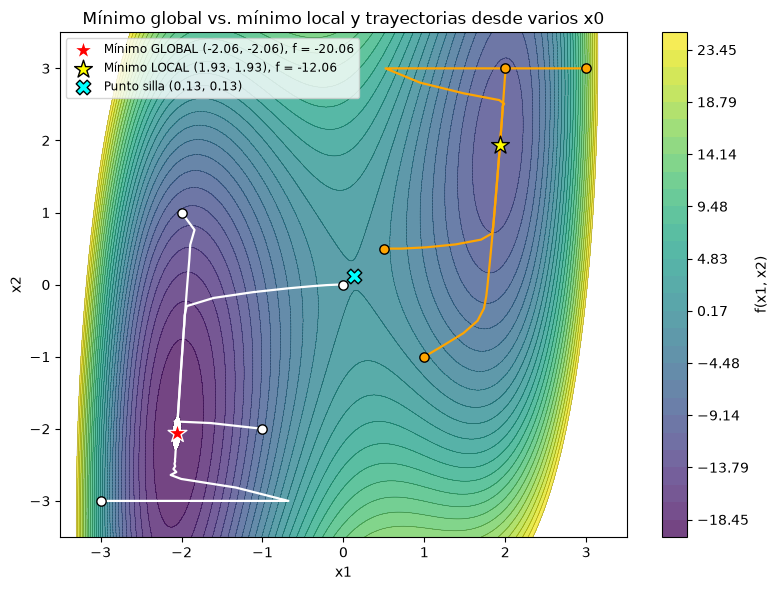

In [7]:
# Visualizamos las curvas de nivel de f(x1, x2) y las trayectorias hacia ambos mínimos
x1_grid = np.linspace(-3.5, 3.5, 300)
x2_grid = np.linspace(-3.5, 3.5, 300)
X1, X2 = np.meshgrid(x1_grid, x2_grid)
Z = (X1**4) - 8.0*(X1**2) + 2.0*X1 + (X2 - X1)**2

plt.figure(figsize=(8, 6))
niveles = np.linspace(-20, 25, 30)
contorno = plt.contourf(X1, X2, Z, levels=niveles, cmap="viridis", alpha=0.75)
plt.colorbar(contorno, label="f(x1, x2)")
plt.contour(X1, X2, Z, levels=niveles, colors="black", linewidths=0.4, alpha=0.4)

# Dibujamos las trayectorias de los puntos iniciales probados
for x0_p, df_m in trayectorias:
    color_linea = "white" if df_m.iloc[-1]["x1"] < 0 else "orange"
    plt.plot(df_m["x1"], df_m["x2"], color=color_linea, linewidth=1.6)
    plt.scatter([x0_p[0]], [x0_p[1]], color=color_linea, edgecolor="black", s=45, zorder=5)

# Marcamos los 3 puntos estacionarios: mínimo global, mínimo local y punto silla
plt.scatter([raices[0]], [raices[0]], color="red", marker="*", s=200, edgecolor="white", zorder=7,
            label=f"Mínimo GLOBAL ({raices[0]:.2f}, {raices[0]:.2f}), f = {f([raices[0], raices[0]]):.2f}")
plt.scatter([raices[2]], [raices[2]], color="yellow", marker="*", s=180, edgecolor="black", zorder=7,
            label=f"Mínimo LOCAL ({raices[2]:.2f}, {raices[2]:.2f}), f = {f([raices[2], raices[2]]):.2f}")
plt.scatter([raices[1]], [raices[1]], color="cyan", marker="X", s=110, edgecolor="black", zorder=7,
            label=f"Punto silla ({raices[1]:.2f}, {raices[1]:.2f})")

plt.title("Mínimo global vs. mínimo local y trayectorias desde varios x0")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.show()

### ¿Cuántos mínimos existen, cuál es el global y cómo lo sabemos?
Al probar varios puntos iniciales, el algoritmo encuentra exactamente **dos mínimos**:
1. **$x^*_1 \approx (-2.059792, -2.059792)$** con **$f(x^*_1) \approx -20.060660$** $\rightarrow$ **Mínimo GLOBAL**.
2. **$x^*_2 \approx (+1.934298, +1.934298)$** con **$f(x^*_2) \approx -12.064586$** $\rightarrow$ **Mínimo LOCAL**.

**¿Cómo sabemos con certeza que $x^*_1$ es el mínimo global?**
1. **Comparación numérica (múltiples arranques):** Todos los puntos iniciales probados en distintas regiones del plano caen en uno de esos dos mínimos, y $f(x^*_1) = -20.060660$ es estrictamente menor que $f(x^*_2) = -12.064586$.
2. **Demostración analítica:**
   * La función crece hacia $+\infty$ en todas direcciones cuando $\|x\| \to \infty$ porque $x_1^4$ domina para valores grandes de $|x_1|$ y $(x_2 - x_1)^2 \ge 0$ siempre suma positivamente; esto garantiza que el mínimo global existe y debe ser un punto estacionario ($\nabla f = 0$).
   * Al resolver $\nabla f(x) = 0$, de $\frac{\partial f}{\partial x_2} = 0$ resulta $x_2 = x_1$, y sustituyendo en $\frac{\partial f}{\partial x_1} = 0$ queda la ecuación cúbica $4x_1^3 - 16x_1 + 2 = 0$, la cual tiene **como máximo 3 raíces reales** (dos mínimos y un punto silla en $x_1 = x_2 \approx 0.1255$).
   * Al no existir ningún otro punto estacionario en todo $\mathbb{R}^2$, el menor de los dos mínimos encontrados es necesariamente el **mínimo global** (el término $+2x_1$ rompe la simetría de $x_1^4 - 8x_1^2$, haciendo más profundo el pozo en $x_1 < 0$).
